# Classification with NN

In [1]:
import os

folder_path = "UTKFace"

for filename in os.listdir(folder_path):
    print(filename)

100_0_0_20170112213500903.jpg
100_0_0_20170112215240346.jpg
100_1_0_20170110183726390.jpg
100_1_0_20170112213001988.jpg
100_1_0_20170112213303693.jpg
100_1_0_20170112215032192.jpg
100_1_0_20170117195420803.jpg
100_1_0_20170119212053665.jpg
100_1_2_20170105174847679.jpg
100_1_2_20170112213615815.jpg
100_1_2_20170112222336458.jpg
101_0_0_20170112213500903.jpg
101_1_2_20170105174739309.jpg
103_0_2_20170112213001988.jpg
105_0_0_20170112213001988.jpg
105_1_0_20170112213001988.jpg
105_1_0_20170112213021902.jpg
105_1_0_20170112213507183.jpg
105_1_1_20170112213303693.jpg
10_0_0_20161220222308131.jpg
10_0_0_20170103200329407.jpg
10_0_0_20170103200522151.jpg
10_0_0_20170103233459275.jpg
10_0_0_20170104013211746.jpg
10_0_0_20170110215927291.jpg
10_0_0_20170110220033115.jpg
10_0_0_20170110220111082.jpg
10_0_0_20170110220235233.jpg
10_0_0_20170110220251986.jpg
10_0_0_20170110220255346.jpg
10_0_0_20170110220316298.jpg
10_0_0_20170110220403810.jpg
10_0_0_20170110220447314.jpg
10_0_0_20170110220503946

In [2]:
import os

folder_path = "UTKFace"

print("Current working directory:", os.getcwd())
print("Folder exists:", os.path.exists(folder_path))
print("Folder path:", os.path.abspath(folder_path))

if os.path.exists(folder_path):
    print("Files:", os.listdir(folder_path)[:10])

Current working directory: c:\Users\user\Downloads
Folder exists: True
Folder path: c:\Users\user\Downloads\UTKFace
Files: ['100_0_0_20170112213500903.jpg', '100_0_0_20170112215240346.jpg', '100_1_0_20170110183726390.jpg', '100_1_0_20170112213001988.jpg', '100_1_0_20170112213303693.jpg', '100_1_0_20170112215032192.jpg', '100_1_0_20170117195420803.jpg', '100_1_0_20170119212053665.jpg', '100_1_2_20170105174847679.jpg', '100_1_2_20170112213615815.jpg']


In [3]:
import os

for root, dirs, files in os.walk(folder_path):
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".gif"))
    ]

    if images:
        print("Folder:", root)
        print("Number of images:", len(images))
        print("Examples:", images[:5])

Folder: UTKFace
Number of images: 23708
Examples: ['100_0_0_20170112213500903.jpg', '100_0_0_20170112215240346.jpg', '100_1_0_20170110183726390.jpg', '100_1_0_20170112213001988.jpg', '100_1_0_20170112213303693.jpg']


In [4]:
import os

folder_path = r"C:\Users\user\Downloads\UTKFace"

renamed_count = 0

for filename in os.listdir(folder_path):
    if filename.lower().endswith(".jpg.chip.jpg"):
        old_path = os.path.join(folder_path, filename)

        new_filename = filename.replace(".jpg.chip.jpg", ".jpg")
        new_path = os.path.join(folder_path, new_filename)

        os.rename(old_path, new_path)
        renamed_count += 1

print(f"Renamed {renamed_count} images successfully.")

Renamed 0 images successfully.


In [5]:
import tensorflow as tf
import os

folder_path = r"C:\Users\user\Downloads\UTKFace"

IMG_SIZE = (48, 48)
BATCH_SIZE = 64

train_data = tf.keras.utils.image_dataset_from_directory(
    folder_path,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

print("Dataset loaded successfully!")

for images in train_data.take(1):
    print("Batch shape:", images.shape)

Found 23708 files.
Dataset loaded successfully!
Batch shape: (64, 48, 48, 3)


## Loading the Data

Loading [Fashion_mnist dataset](https://www.tensorflow.org/datasets/catalog/fashion_mnist)

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.utils import to_categorical

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

Data = "/downloads"
train_dir = os.path.join(Data, "crop_part1")
test_dir = os.path.join(Data, "UTKFace")


In [8]:
import os

folder_path = r"C:\Users\user\Downloads\UTKFace"

files = os.listdir(folder_path)

print("Total files:", len(files))
print("First 10 files:", files[:10])

valid_images = [
    f for f in files
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".gif"))
]

print("Recognized image extensions:", len(valid_images))

Total files: 23708
First 10 files: ['100_0_0_20170112213500903.jpg', '100_0_0_20170112215240346.jpg', '100_1_0_20170110183726390.jpg', '100_1_0_20170112213001988.jpg', '100_1_0_20170112213303693.jpg', '100_1_0_20170112215032192.jpg', '100_1_0_20170117195420803.jpg', '100_1_0_20170119212053665.jpg', '100_1_2_20170105174847679.jpg', '100_1_2_20170112213615815.jpg']
Recognized image extensions: 23708


In [9]:
import os
import tensorflow as tf

folder_path = r"C:\Users\user\Downloads\UTKFace"

IMG_SIZE = (48, 48)
BATCH_SIZE = 64

image_paths = [
    os.path.join(folder_path, f)
    for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".gif"))
]

print("Images found:", len(image_paths))

def load_image(path):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image

train_data = (
    tf.data.Dataset.from_tensor_slices(image_paths)
    .shuffle(len(image_paths), seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

for images in train_data.take(1):
    print("Batch shape:", images.shape)

Images found: 23708
Batch shape: (64, 48, 48, 3)


In [10]:
import os
import tensorflow as tf

folder_path = r"C:\Users\user\Downloads\UTKFace"

IMG_SIZE = (48, 48)
BATCH_SIZE = 64

# Get all image paths
image_paths = [
    os.path.join(folder_path, f)
    for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Images found:", len(image_paths))

# Load and preprocess each image
def load_image(path):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image

# Create TensorFlow dataset
train_data = tf.data.Dataset.from_tensor_slices(image_paths)

train_data = (
    train_data
    .shuffle(1000, seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Verify
for images in train_data.take(1):
    print("Batch shape:", images.shape)

print("Dataset loaded successfully!")

Images found: 23708
Batch shape: (64, 48, 48, 3)
Dataset loaded successfully!


In [11]:

import os
import pandas as pd

folder_path = r"C:\Users\user\Downloads\UTKFace"

data = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith(".jpg"):
        try:
            age = int(filename.split("_")[0])

            if 0 <= age <= 12:
                age_group = 0
            elif age <= 19:
                age_group = 1
            elif age <= 35:
                age_group = 2
            elif age <= 60:
                age_group = 3
            else:
                age_group = 4

            data.append({
                "filename": filename,
                "age": age,
                "age_group": age_group
            })
        except (ValueError, IndexError):
            continue

df = pd.DataFrame(data)

print("Total images:", len(df))
print("\nAge group distribution:")
print(df["age_group"].value_counts().sort_index())


Total images: 23708

Age group distribution:
age_group
0     3413
1     1180
2    10514
3     6204
4     2397
Name: count, dtype: int64


In [82]:
import tensorflow as tf
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

tf.keras.utils.set_random_seed(42)

IMG_SIZE = (48, 48)
BATCH_SIZE = 64

train_data = tf.keras.utils.image_dataset_from_directory(
    folder_path,
    seed=42,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_data = tf.keras.utils.image_dataset_from_directory(
    folder_path,
    validation_split=0.10,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_data = tf.keras.utils.image_dataset_from_directory(
    folder_path,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_data.class_names
NUM_CLASSES = len(class_names)

AUTOTUNE = tf.data.AUTOTUNE

train_data = train_data.prefetch(AUTOTUNE)
val_data = val_data.prefetch(AUTOTUNE)
test_data = test_data.prefetch(AUTOTUNE)

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)


Found 0 files belonging to 0 classes.


ValueError: No images found in directory C:\Users\user\Downloads\UTKFace. Allowed formats: ('.bmp', '.gif', '.jpeg', '.jpg', '.png')

In [14]:

import os

folder_path = r"C:\Users\user\Downloads\UTKFace"

print("Folder exists:", os.path.exists(folder_path))
print("Folder contents:", os.listdir(folder_path)[:20])

# Count supported images, including nested folders
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

images = []
for root, dirs, files in os.walk(folder_path):
    for file in files:
        if file.lower().endswith(extensions):
            images.append(os.path.join(root, file))

print("Total images found:", len(images))
print("First 5 images:", images[:5])



Folder exists: True
Folder contents: ['100_0_0_20170112213500903.jpg', '100_0_0_20170112215240346.jpg', '100_1_0_20170110183726390.jpg', '100_1_0_20170112213001988.jpg', '100_1_0_20170112213303693.jpg', '100_1_0_20170112215032192.jpg', '100_1_0_20170117195420803.jpg', '100_1_0_20170119212053665.jpg', '100_1_2_20170105174847679.jpg', '100_1_2_20170112213615815.jpg', '100_1_2_20170112222336458.jpg', '101_0_0_20170112213500903.jpg', '101_1_2_20170105174739309.jpg', '103_0_2_20170112213001988.jpg', '105_0_0_20170112213001988.jpg', '105_1_0_20170112213001988.jpg', '105_1_0_20170112213021902.jpg', '105_1_0_20170112213507183.jpg', '105_1_1_20170112213303693.jpg', '10_0_0_20161220222308131.jpg']
Total images found: 23708
First 5 images: ['C:\\Users\\user\\Downloads\\UTKFace\\100_0_0_20170112213500903.jpg', 'C:\\Users\\user\\Downloads\\UTKFace\\100_0_0_20170112215240346.jpg', 'C:\\Users\\user\\Downloads\\UTKFace\\100_1_0_20170110183726390.jpg', 'C:\\Users\\user\\Downloads\\UTKFace\\100_1_0_2017

In [5]:
# plot an image
import matplotlib.pyplot as plt



Total valid images: 23708

Age group distribution:
age_group
0     3413
1     1180
2    10514
3     6204
4     2397
Name: count, dtype: int64

Training images: 18966
Validation images: 2371
Test images: 2371

Image batch shape: (64, 48, 48, 1)
Label batch shape: (64,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,589 (1.36 MB)

 Trainable params: 355,589 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


297/297 ━━━━━━━━━━━━━━━━━━━━ 59s 187ms/step - accuracy: 0.5548 - loss: 1.1161 - val_accuracy: 0.6478 - val_loss: 0.8897
Epoch 2/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 82ms/step - accuracy: 0.6622 - loss: 0.8569 - val_accuracy: 0.6744 - val_loss: 0.8015
Epoch 3/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 82ms/step - accuracy: 0.6949 - loss: 0.7666 - val_accuracy: 0.6879 - val_loss: 0.7453
Epoch 4/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 81ms/step - accuracy: 0.7140 - loss: 0.7107 - val_accuracy: 0.7115 - val_loss: 0.7125
Epoch 5/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 25s 83ms/step - accuracy: 0.7349 - loss: 0.6643 - val_accuracy: 0.7178 - val_loss: 0.6803
Epoch 6/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 25s 84ms/step - accuracy: 0.7426 - loss: 0.6360 - val_accuracy: 0.7174 - val_loss: 0.6913
Epoch 7/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 25s 84ms/step - accuracy: 0.7566 - loss: 0.5974 - val_accuracy: 0.7275 - val_loss: 0.6649
Epoch 8/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 25s 85ms/step - accuracy: 0.7727 - loss: 0.5684 - val_accura

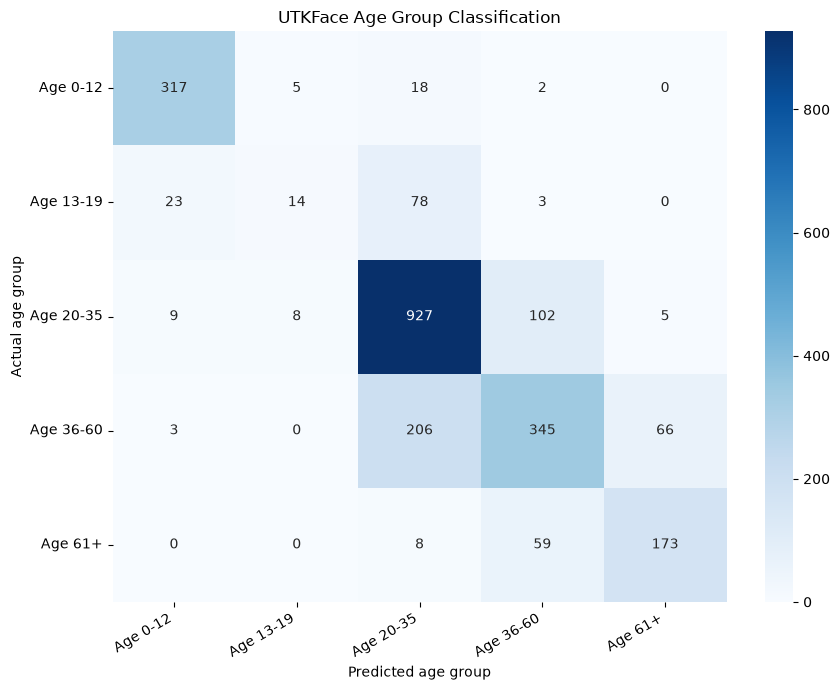

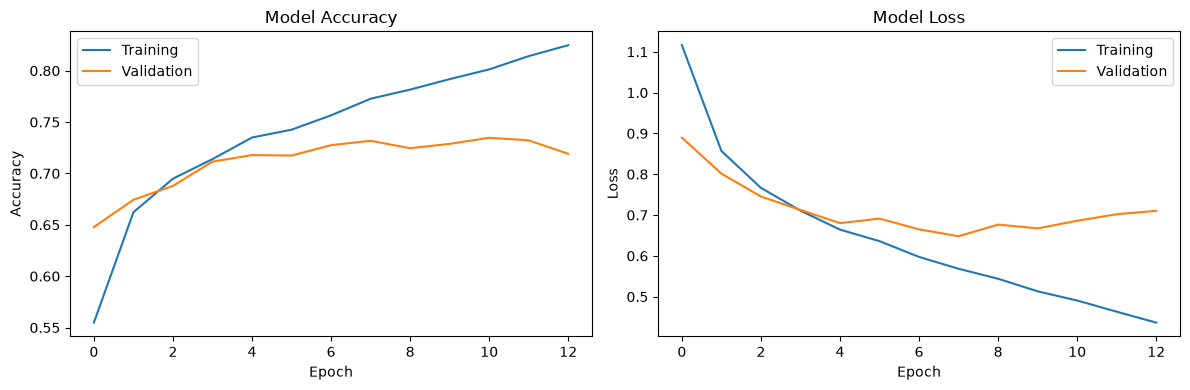

In [ ]:

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Conv2D, MaxPooling2D, Dropout, Flatten

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Configuration
folder_path = r"C:\Users\user\Downloads\UTKFace"
IMG_SIZE = (48, 48)
BATCH_SIZE = 34
AUTOTUNE = tf.data.AUTOTUNE

# --------------------------------------------------
# 1. Read filenames and extract AGE only
# --------------------------------------------------
data = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
        try:
            age = int(filename.split("_")[0])

            if 0 <= age <= 12:
                age_group = 0
            elif age <= 19:
                age_group = 1
            elif age <= 35:
                age_group = 2
            elif age <= 60:
                age_group = 3
            else:
                age_group = 4

            data.append({
                "filename": filename,
                "age": age,
                "age_group": age_group
            })

        except (ValueError, IndexError):
            continue

df = pd.DataFrame(data)

if df.empty:
    raise ValueError("No valid UTKFace images or age labels were found.")

print("Total valid images:", len(df))
print("\nAge group distribution:")
print(df["age_group"].value_counts().sort_index())

# --------------------------------------------------
# 2. Split into training, validation, and test sets
#    80% training, 10% validation, 10% testing
# --------------------------------------------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["age_group"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["age_group"]
)

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

# --------------------------------------------------
# 3. Load and preprocess images
# --------------------------------------------------
def load_image(filename, age_group):
    path = tf.strings.join([folder_path, filename], separator=os.sep)

    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )
    image.set_shape([None, None, 1])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, age_group

def make_dataset(frame, training=False):
    filenames = frame["filename"].to_numpy()
    labels = frame["age_group"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (filenames, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(frame),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_data = make_dataset(train_df, training=True)
val_data = make_dataset(val_df)
test_data = make_dataset(test_df)

# Check a batch
for images, labels in train_data.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

# --------------------------------------------------
# 4. Build CNN for AGE GROUP classification
# --------------------------------------------------
NUM_CLASSES = 5

model = Sequential([
    Input(shape=(48, 48, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# --------------------------------------------------
# 5. Train model with early stopping
# --------------------------------------------------
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=30,
    callbacks=[early_stopping]
)

# --------------------------------------------------
# 6. Evaluate on the independent test set
# --------------------------------------------------
test_loss, test_accuracy = model.evaluate(test_data)

print("\nTest loss:", test_loss)
print("Test accuracy:", test_accuracy)

# --------------------------------------------------
# 7. Predictions and classification report
# --------------------------------------------------
y_true = np.concatenate([
    labels.numpy() for images, labels in test_data
])

y_prob = model.predict(test_data)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "Age 0-12",
    "Age 13-19",
    "Age 20-35",
    "Age 36-60",
    "Age 61+"
]

print("\nAccuracy:", accuracy_score(y_true, y_pred))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

# --------------------------------------------------
# 8. Confusion matrix
# --------------------------------------------------
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted age group")
plt.ylabel("Actual age group")
plt.title("UTKFace Age Group Classification")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. Plot training performance
# --------------------------------------------------
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [13]:
model.save("utkface_age_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [15]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Conv2D, MaxPooling2D, Dropout, Flatten


In [17]:
tf.keras.utils.set_random_seed(42)

# Configuration
folder_path = r"C:\Users\user\Downloads\UTKFace"
IMG_SIZE = (48, 48)
BATCH_SIZE = 34
AUTOTUNE = tf.data.AUTOTUNE

In [18]:
data = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
        try:
            age = int(filename.split("_")[0])

            if 0 <= age <= 12:
                age_group = 0
            elif age <= 19:
                age_group = 1
            elif age <= 35:
                age_group = 2
            elif age <= 60:
                age_group = 3
            else:
                age_group = 4

            data.append({
                "filename": filename,
                "age": age,
                "age_group": age_group
            })

        except (ValueError, IndexError):
            continue

df = pd.DataFrame(data)

if df.empty:
    raise ValueError("No valid UTKFace images or age labels were found.")


print("Total valid images:", len(df))
print("\nAge group distribution:")
print(df["age_group"].value_counts().sort_index())


Total valid images: 23708

Age group distribution:
age_group
0     3413
1     1180
2    10514
3     6204
4     2397
Name: count, dtype: int64


In [27]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["age_group"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.30,
    random_state=42,
    stratify=temp_df["age_group"]
)

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))


Training images: 16595
Validation images: 4979
Test images: 2134


In [29]:
def load_image(filename, age_group):
    path = tf.strings.join([folder_path, filename], separator=os.sep)

    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )
    image.set_shape([None, None, 1])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 15.0

    return image, age_group

def make_dataset(frame, training=False):
    filenames = frame["filename"].to_numpy()
    labels = frame["age_group"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (filenames, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(frame),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_data = make_dataset(train_df, training=True)
val_data = make_dataset(val_df)
test_data = make_dataset(test_df)

# Check a batch
for images, labels in train_data.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)


Image batch shape: (34, 48, 48, 1)
Label batch shape: (34,)


## Classification

In [74]:
NUM_CLASSES = 5

model = Sequential([
    Input(shape=(48, 48, 1)),

    Conv2D(20, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    

    

    Flatten(),
    Dense(10, activation="relu"),
    

    Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[ "accuracy"]
)

model.summary()


Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_25 (Conv2D)              │ (None, 46, 46, 20)     │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 23, 23, 20)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_19 (Flatten)            │ (None, 10580)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 10)             │       105,810 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 5)              │            55 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,065 (414.32 KB)

 Trainable params: 106,065 (414.32 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    callbacks=[early_stopping]
)

Epoch 1/5


c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


489/489 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.4261 - loss: 1.5556 - val_accuracy: 0.4435 - val_loss: 1.4489
Epoch 2/5
489/489 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.4434 - loss: 1.4153 - val_accuracy: 0.4435 - val_loss: 1.3928
Epoch 3/5
489/489 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - accuracy: 0.4434 - loss: 1.3862 - val_accuracy: 0.4435 - val_loss: 1.3778
Epoch 4/5
489/489 ━━━━━━━━━━━━━━━━━━━━ 14s 28ms/step - accuracy: 0.4434 - loss: 1.3754 - val_accuracy: 0.4435 - val_loss: 1.3735
Epoch 5/5
489/489 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.4434 - loss: 1.3729 - val_accuracy: 0.4435 - val_loss: 1.3722


In [73]:
test_loss, test_accuracy = model.evaluate(test_data)

print("\nTest loss:", test_loss)
print("Test accuracy:", test_accuracy)

# --------------------------------------------------
# 7. Predictions and classification report
# --------------------------------------------------
y_true = np.concatenate([
    labels.numpy() for images, labels in test_data
])

y_prob = model.predict(test_data)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "Age 0-12",
    "Age 13-19",
    "Age 20-35",
    "Age 36-60",
    "Age 61+"
]

print("\nAccuracy:", accuracy_score(y_true, y_pred))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

 1/63 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.6176 - loss: 0.9565

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.5923 - loss: 1.0312

Test loss: 1.0312142372131348
Test accuracy: 0.5923148989677429
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step

Accuracy: 0.5923149015932521

Classification report:
              precision    recall  f1-score   support

    Age 0-12       0.54      0.87      0.67       307
   Age 13-19       0.00      0.00      0.00       106
   Age 20-35       0.66      0.89      0.76       947
   Age 36-60       0.42      0.28      0.34       558
     Age 61+       0.00      0.00      0.00       216

    accuracy                           0.59      2134
   macro avg       0.33      0.41      0.35      2134
weighted avg       0.48      0.59      0.52      2134



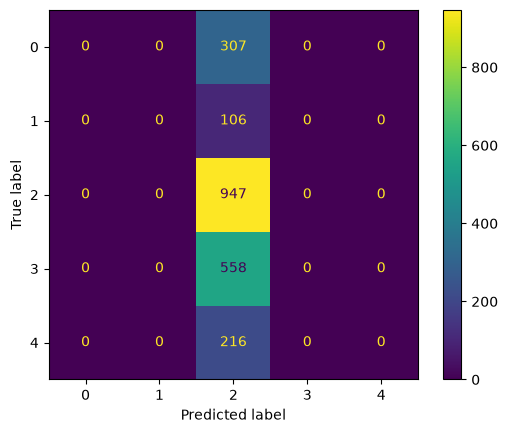

In [65]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
#import seaborn as sns
ConfusionMatrixDisplay.from_predictions(y_true,
    y_pred);

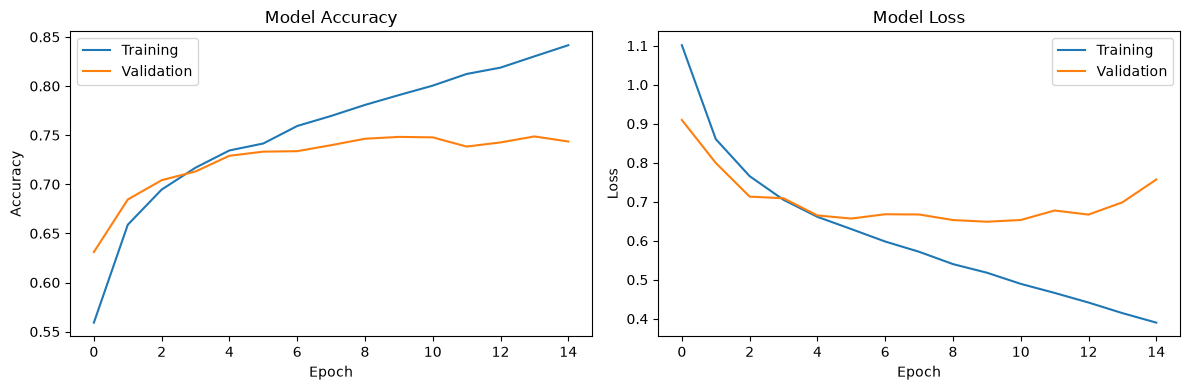

In [23]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [24]:
print("Total rows in df:", len(df))
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

Total rows in df: 23708
Training rows: 21337
Validation rows: 2133
Test rows: 238


In [ ]:
model.save("utkface_age_model.keras")
print("Model saved successfully!")

In [25]:

import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

# -----------------------------
# Page configuration
# -----------------------------
st.set_page_config(
    page_title="Age Prediction App",
    page_icon="🎂",
    layout="centered"
)

# -----------------------------
# Load trained model
# -----------------------------
@st.cache_resource
def load_model():
    return tf.keras.models.load_model("utkface_age_model.keras")

try:
    model = load_model()
except Exception as e:
    st.error(f"Could not load model: {e}")
    st.stop()

# -----------------------------
# Age groups
# -----------------------------
age_groups = [
    "0–12 years",
    "13–19 years",
    "20–35 years",
    "36–60 years",
    "61+ years"
]

# -----------------------------
# App interface
# -----------------------------
st.title("🎂 Age Prediction System")

st.write(
    "Upload a face image and let the trained CNN "
    "predict its age group."
)

st.info(
    "This model predicts age groups only. "
    "It does not predict gender or ethnicity."
)

uploaded_file = st.file_uploader(
    "Choose a face image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    try:
        # Display uploaded image
        image = Image.open(uploaded_file).convert("L")

        st.image(
            uploaded_file,
            caption="Uploaded image",
            width=300
        )

        # Preprocess exactly as during training
        image = image.resize((48, 48))

        image_array = np.array(
            image,
            dtype=np.float32
        ) / 255.0

        image_array = np.expand_dims(
            image_array, axis=-1
        )

        image_array = np.expand_dims(
            image_array, axis=0
        )

        # Predict age group
        if st.button("Predict Age Group", type="primary"):

            with st.spinner("Analyzing image..."):
                predictions = model.predict(
                    image_array,
                    verbose=0
                )

            predicted_class = int(
                np.argmax(predictions[0])
            )

            confidence = float(
                predictions[0][predicted_class]
            ) * 100

            st.success("Prediction completed!")

            st.subheader("Predicted Age Group")

            st.markdown(
                f"## 🎯 {age_groups[predicted_class]}"
            )

            st.metric(
                "Model confidence",
                f"{confidence:.2f}%"
            )

            st.caption(
                "Confidence is the model's softmax score, "
                "not a guarantee that the prediction is correct."
            )

            # Show scores for all age groups
            st.subheader("Scores for Each Age Group")

            score_data = {
                "Age group": age_groups,
                "Score (%)": (
                    predictions[0] * 100
                ).round(2)
            }

            st.bar_chart(
                score_data,
                x="Age group",
                y="Score (%)"
            )

    except Exception as e:
        st.error(f"Could not process this image: {e}")

st.divider()

st.caption(
    "UTKFace Age Classification | CNN Deep Learning Project"
)


2026-10-27 22:40:45.254 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 22:40:45.256 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 22:40:45.582 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 22:40:46.141 
  command:

    streamlit run c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-27 22:40:46.142 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 22:40:46.142 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-27 22:

DeltaGenerator()